In [1]:
import spacy
import numpy as np

# Load a pre-trained word embedding model (spaCy's small English model)
nlp = spacy.load("en_core_web_sm")

def average_embedding(sentence):
  doc = nlp(sentence)
  vectors = [token.vector for token in doc if token.has_vector]  # Exclude stopwords without vectors
  return np.mean(vectors,axis=0) if vectors else np.zeros((nlp.vocab.vectors_length,))


# Example sentence
sentence = "The dog runs fast"
embedding = average_embedding(sentence)

print("Sentence Embedding (Averaging):", embedding[:5])  # Print first 5 values


Sentence Embedding (Averaging): [ 0.16034171 -0.06278075 -0.51387095 -0.10410072  0.00280273]


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Sample corpus
corpus = [
    "The dog runs fast",
    "A cat sleeps on the sofa",
    "Dogs and cats are great pets"
]

# Compute TF-IDF Scores
vector = TfidfVectorizer()
vector.fit(corpus)
tfidf_scores = vector.transform([sentence]).toarray()[0]
words = vector.get_feature_names_out()

# Compute weighted embedding
def tfidf_weighted_embedding(sentence):
  doc = nlp(sentence)
  word_embedding = []
  weights = []

  for token in doc:
    word = token.text.lower()
    if word in words and token.has_vector:
      idx = list(words).index(word)
      word_embedding.append(token.vector*tfidf_scores[idx])
      weights.append(tfidf_scores[idx])

  return np.sum(word_embedding,axis=0)/np.sum(weights) if weights else np.zeros((nlp.vocab.vectors_length,))

embedding = tfidf_weighted_embedding(sentence)

print("Sentence Embedding (TF-IDF Weighted):", embedding[:5])  # Print first 5 values

Sentence Embedding (TF-IDF Weighted): [ 0.14707127 -0.04034225 -0.53884666 -0.15503714  0.03409252]


Reduced Sentence Embedding (PCA): [-1.2933475e+00 -1.3441613e+00 -1.7296577e-07]


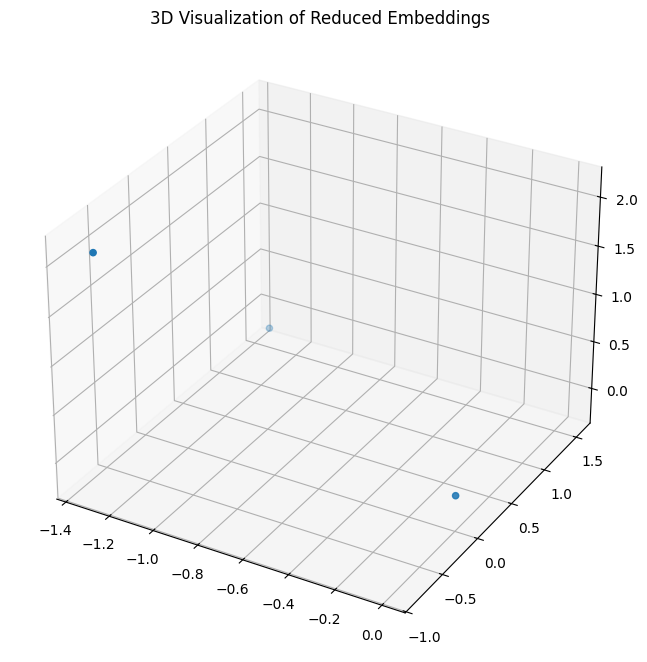

In [3]:
from sklearn.decomposition import PCA

# Generate embeddings for all sentences in corpus
sent_embedding = np.array([average_embedding(sent) for sent in corpus])

# Apply PCA to reduce dimensions (e.g., from 300 to 50)
pca = PCA()
reduced_embedding = pca.fit_transform(sent_embedding)

print("Reduced Sentence Embedding (PCA):", reduced_embedding[0][:5])  # Print first 5 values

import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 10))

ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    reduced_embedding[0],
    reduced_embedding[1],
    reduced_embedding[2]
)
ax.set_title("3D Visualization of Reduced Embeddings")

plt.show()

In [4]:
from sentence_transformers import SentenceTransformer

# Load pre-trained SBERT model
model = SentenceTransformer("all-MiniLM-L6-v2")

# Compute SBERT embedding
sentence = "The dog runs fast"
embedding = model.encode(sentence)

print("Sentence Embedding (SBERT):", embedding[:5])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence Embedding (SBERT): [0.03234609 0.03101399 0.01024306 0.03830507 0.00155679]


In [5]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# Load pre-trained SBERT Model
model = SentenceTransformer("all-MiniLM-L6-v2")

def compute_similarity(sentence1,sentence2):
  # encode sentences into embeddings
  embedding1 = model.encode(sentence1)
  embedding2 = model.encode(sentence2)

  # compute cosine similarity
  similarity_score = cosine_similarity([embedding1],[embedding2])[0][0]

  return similarity_score

# Example sentences
sentence1 = "A dog is running in the park ."
sentence2 = "A pup is playing in the park."

# Compute similarity
similarity = compute_similarity(sentence1, sentence2)

print(f"Sentence Similarity Score (SBERT): {similarity:.4f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence Similarity Score (SBERT): 0.8210
